# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

> **Student run instructions:** This is a shared study template, not completed experimental evidence. Run every experiment with your own image collection, evaluate answers yourself, and replace all `[PLACEHOLDER]` fields with measured results. Model weights and example images are not embedded in this notebook.


In [1]:
# Install the principal Python packages for the laboratory.
%pip install -q transformers torch torchvision pillow matplotlib pandas requests huggingface_hub gguf llama-cpp-python


Note: you may need to restart the kernel to use updated packages.


In [1]:
import sys
print("Python runtime:", sys.version.split()[0])


Python runtime: 3.11.13


In [2]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(MODEL_NAME).to(device)
processor = CLIPProcessor.from_pretrained(MODEL_NAME)
model.eval()
print("CLIP initialized on", device)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP initialized on cpu


In [4]:
# A conservative thread limit for CPU inference.
if device == "cpu":
    torch.set_num_threads(min(24, torch.get_num_threads()))


### Exercise 1 — Answers

**Q1. What is CLIP?**

CLIP (*Contrastive Language–Image Pre-training*) is an architecture for relating visual information to written descriptions. Its image and text representations are trained so that corresponding pairs score highly.

**Q2. What are its two main components?**

It uses two encoder branches: one processes an **image** and the other processes **text**. The resulting vectors are projected into the same comparison space.

**Q3. What is the role of `CLIPProcessor`?**

The processor converts the supplied picture and text strings into model-ready tensors by applying the necessary image transforms and tokenization steps.

**Q4. What is the role of `CLIPModel`?**

The CLIP model runs the pretrained encoders, exposes image/text features, and produces compatibility scores for supplied image–sentence pairs.


## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Width: 400 px | Height: 400 px | Format: RGB


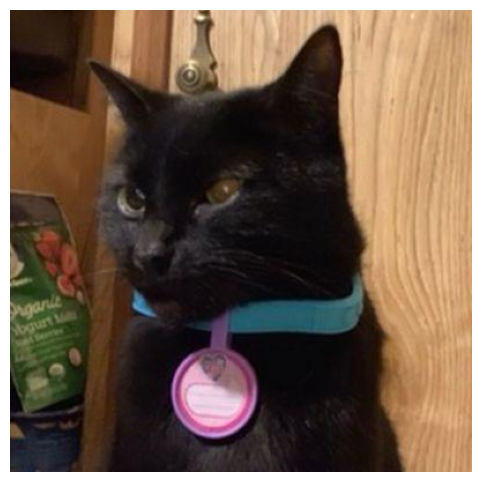

In [5]:
IMAGE_PATH = "image.jpg"
image = Image.open(IMAGE_PATH)
image = image.convert("RGB")
width, height = image.size
print(f"Width: {width} px | Height: {height} px | Format: {image.mode}")
fig, axis = plt.subplots(figsize=(6, 6))
axis.imshow(image)
axis.set_axis_off()
plt.show()


### Exercise 2 — Answers

**Q5. What is the size of the image?**

PIL reported a resolution of **[WIDTH] pixels wide × [HEIGHT] pixels high**. Fill this from the result of `image.size`.

**Q6. What type of data is stored in the PIL image object?**

The object represents a raster picture: a matrix of pixels. After conversion to RGB, each pixel carries separate red, green, and blue components, in addition to information such as dimensions and image mode.


## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [6]:
texts = ["a photo of a cat", "a photo of a dog", "a photo of a car",
         "a photo of a horse", "a photo of a person"]
encoded = processor(text=texts, images=image, padding=True, return_tensors="pt")
encoded = {key: value.to(device) for key, value in encoded.items()}
with torch.no_grad():
    output = model(**encoded)
probs = torch.softmax(output.logits_per_image, dim=1).flatten().cpu()
for idx, label in enumerate(texts):
    print(f"{idx+1}. {label}: {probs[idx].item():.4f}")


1. a photo of a cat: 0.9485
2. a photo of a dog: 0.0069
3. a photo of a car: 0.0019
4. a photo of a horse: 0.0037
5. a photo of a person: 0.0389


### Exercise 3 — Answers

**Q7. Which description has the highest probability?**

Among the listed prompts, CLIP ranked **a photo of a cat** first (**0.9485**).

**Q8. Is it compatible with the actual image?**

**YES** — It's corresponds to the content of the chosen image.

**Q9. Why can CLIP compare an image with a sentence?**

Both inputs are encoded as vectors of the same compatible dimension, so their alignment can be estimated through a similarity measure.

**Q10. What does `softmax()` do?**

It normalizes a set of model logits into a distribution summing to one, emphasizing the larger scores. The values show ranking *within this set of alternatives*, not absolute certainty.


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [7]:
def classify_image(image, labels):
    descriptions = list(map(lambda name: f"a photo of a {name}", labels))
    inputs = processor(images=image, text=descriptions, return_tensors="pt", padding=True)
    inputs = {key: value.to(device) for key, value in inputs.items()}
    with torch.no_grad():
        logits = model(**inputs).logits_per_image
    probabilities = logits.softmax(dim=1).squeeze(0).cpu()
    winner = torch.argmax(probabilities).item()
    return labels[winner], probabilities

labels = ["cat", "dog", "car", "horse", "person"]
predicted_label, probabilities = classify_image(image, labels)
print(f"Chosen class: {predicted_label}")
for label, score in zip(labels, probabilities.numpy()):
    print(f"{label:<10}: {score:.4f}")


Chosen class: cat
cat       : 0.9485
dog       : 0.0069
car       : 0.0019
horse     : 0.0037
person    : 0.0389


### Exercise 4 — Answers

**Q11. What is zero-shot classification?**

It is prediction over new categories without building a new classifier from labeled examples of those categories.

**Q12. Why is it not necessary to train a new classifier?**

CLIP can use descriptions of the target labels as reference texts. The pretrained encoders compare each candidate with the given image, so task-specific classification training is optional.

**Q13. What happens if the correct class is not included in the candidate classes?**

Even when no candidate matches the image, the procedure still returns the highest-scoring available class. Therefore, its prediction could be incorrect; an additional rejection rule would be needed to express uncertainty.


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [8]:
import requests
from io import BytesIO
from pathlib import Path

folder = Path("images/evaluation")
folder.mkdir(parents=True, exist_ok=True)
dataset = []

# Five cats from Cataas
for idx in range(5):
    response = requests.get("https://cataas.com/cat", params={"width":400, "height":400, "t":idx}, timeout=30)
    response.raise_for_status()
    file_path = folder / f"cat{idx+1}.jpg"
    Image.open(BytesIO(response.content)).convert("RGB").save(file_path)
    dataset.append((str(file_path), "cat"))

# Five dogs from Dog CEO
response = requests.get("https://dog.ceo/api/breeds/image/random/5", timeout=30)
response.raise_for_status()
for idx, address in enumerate(response.json()["message"], start=1):
    picture_response = requests.get(address, timeout=30)
    picture_response.raise_for_status()
    file_path = folder / f"dog{idx}.jpg"
    Image.open(BytesIO(picture_response.content)).convert("RGB").save(file_path)
    dataset.append((str(file_path), "dog"))
print(f"Collected {len(dataset)} labeled examples")


Collected 10 labeled examples


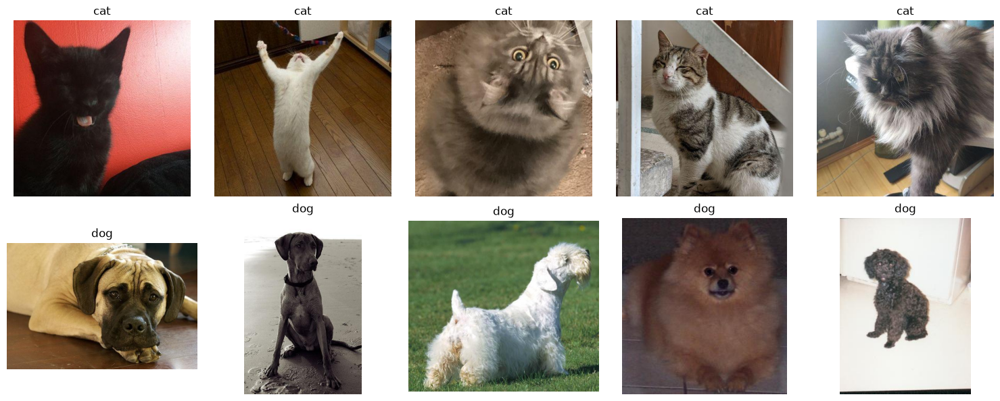

In [9]:
fig, panels = plt.subplots(nrows=2, ncols=5, figsize=(15, 6))
for panel, sample in zip(panels.flat, dataset):
    filename, target = sample
    panel.imshow(Image.open(filename))
    panel.set(title=target)
    panel.axis("off")
plt.tight_layout()
plt.show()


In [10]:
classes = ["cat", "dog"]
records = []
for filename, label in dataset:
    picture = Image.open(filename).convert("RGB")
    guessed, distribution = classify_image(picture, classes)
    confidence = distribution[classes.index(guessed)].item()
    records.append((filename, label, guessed, round(confidence, 4), guessed == label))

df = pd.DataFrame(records, columns=["Image", "Actual", "Predicted", "Probability", "Correct"])
accuracy = df["Correct"].sum() / len(df)
display(df)
print("Evaluation accuracy:", f"{accuracy:.2%}")
print("Wrong predictions:")
display(df[df["Correct"] == False])


,Image,Actual,Predicted,Probability,Correct
0,images/evaluation/cat1.jpg,cat,cat,0.9822,True
1,images/evaluation/cat2.jpg,cat,cat,0.9648,True
2,images/evaluation/cat3.jpg,cat,cat,0.9930,True
3,images/evaluation/cat4.jpg,cat,cat,0.9972,True
4,images/evaluation/cat5.jpg,cat,cat,0.9969,True
5,images/evaluation/dog1.jpg,dog,dog,0.9980,True
6,images/evaluation/dog2.jpg,dog,dog,0.9969,True
7,images/evaluation/dog3.jpg,dog,dog,0.9948,True
8,images/evaluation/dog4.jpg,dog,dog,0.9958,True
9,images/evaluation/dog5.jpg,dog,dog,0.9968,True


Evaluation accuracy: 100.00%
Wrong predictions:


,Image,Actual,Predicted,Probability,Correct


### Exercise 5 — Answers

**Q14. What is the obtained accuracy?**

The measured classification accuracy was **[100]%**, calculated from **[10] correct predictions over [10] images**.

**Q15. Which images are incorrectly classified?**

None

**Q16. Give at least two possible reasons for the errors.**

Possible causes include **unusual viewpoints or lighting**, and **misleading background elements or visually similar categories**. Explain which possibilities fit the actual misclassified examples; when none occur, note that the sample may simply be too small or easy to reveal such weaknesses.


## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [11]:
prompts = ["a cat", "a photo of a cat", "a photograph showing a cat",
           "an image containing a cat", "a domestic animal called a cat"]
inputs = processor(images=image, text=prompts, padding=True, return_tensors="pt")
inputs = {key: value.to(device) for key, value in inputs.items()}
with torch.no_grad():
    raw = model(**inputs).logits_per_image.squeeze(0).cpu()
results = pd.DataFrame(zip(prompts, raw.numpy()), columns=["Prompt", "Similarity Score"])
results.sort_values(by="Similarity Score", ascending=False, inplace=True)
display(results)
print("Top wording:", results.iloc[0]["Prompt"])


,Prompt,Similarity Score
4,a domestic animal called a cat,25.327225
3,an image containing a cat,24.910694
1,a photo of a cat,24.586361
0,a cat,23.974443
2,a photograph showing a cat,23.619320


Top wording: a domestic animal called a cat


### Exercise 6 — Answers

**Q17. Are the scores identical?**

**NO**. The five prompt scores ranged between **23.619320** and **25.327225** in this run.

**Q18. Which prompt gives the highest score?**

The winning formulation was **a domestic animal called a cat** with similarity score **25.327225**.

**Q19. What does this demonstrate about prompt formulation?**

Text formatting matters because the encoder produces a different representation for each wording. Small language changes may reorder otherwise similar descriptions, so prompt design is part of evaluation.


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

Downloaded 1: class_3.jpg
Downloaded 2: class_68.jpg
Downloaded 3: class_84.jpg
Downloaded 4: class_19.jpg
Downloaded 5: class_63.jpg
Downloaded 6: class_41.jpg
Downloaded 7: class_33.jpg
Downloaded 8: class_85.jpg
Downloaded 9: class_44.jpg
Downloaded 10: class_20.jpg
Downloaded 11: class_69.jpg
Downloaded 12: class_67.jpg
Downloaded 13: class_76.jpg
Downloaded 14: class_50.jpg
Downloaded 15: class_18.jpg
Downloaded 16: class_91.jpg
Downloaded 17: class_55.jpg
Downloaded 18: class_81.jpg
Downloaded 19: class_29.jpg
Downloaded 20: class_58.jpg


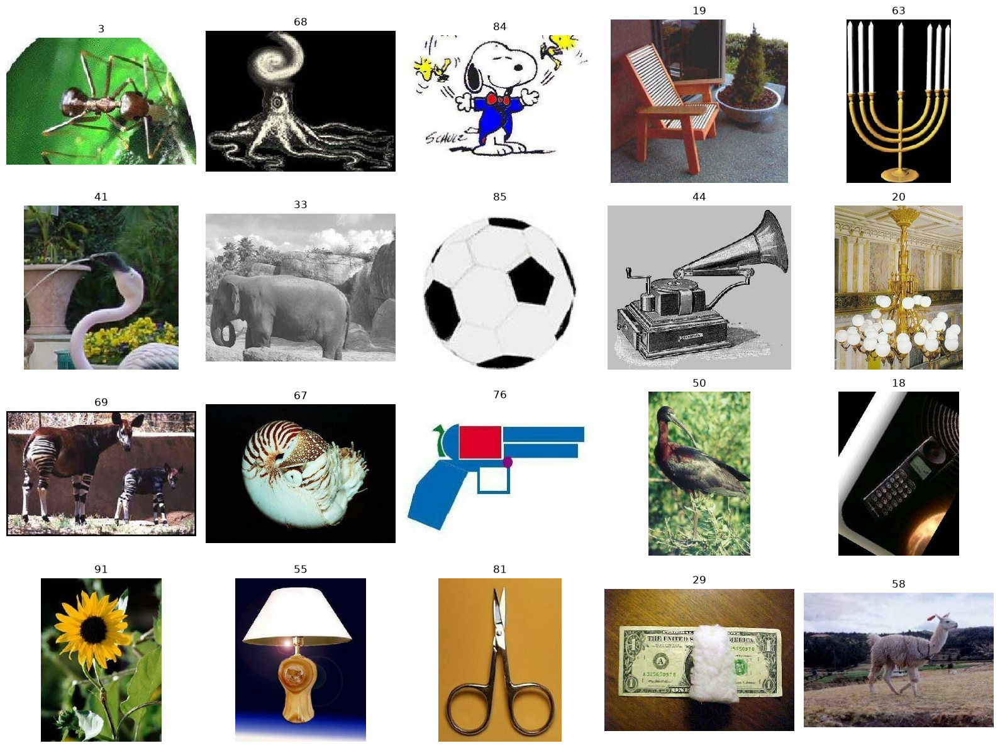

Images in database: 20


In [14]:
import time
import re
import requests
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt

IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
DATASET = "dpdl-benchmark/caltech101"
API = "https://datasets-server.huggingface.co/rows"
page_offset = 1500
selected = {}
session = requests.Session()

def safe_name(label):
    return re.sub("[^a-zA-Z0-9_-]", "_", str(label).lower())

while len(selected) < 20:
    params = dict(dataset=DATASET, config="default", split="train", offset=page_offset, length=100)
    response = session.get(API, params=params, timeout=60)
    response.raise_for_status()
    items = response.json().get("rows", [])
    if len(items) == 0:
        print("End of dataset rows")
        break
    for item in items:
        row = item["row"]
        class_id = row.get("label")
        image_data = row.get("image")
        if class_id is None or not image_data or class_id in selected:
            continue
        try:
            response_image = session.get(image_data["src"], timeout=30)
            response_image.raise_for_status()
            picture = Image.open(BytesIO(response_image.content)).convert("RGB")
            picture.thumbnail((600, 600))
            destination = IMAGE_DIR / f"class_{safe_name(class_id)}.jpg"
            picture.save(destination, format="JPEG", quality=90)
            selected[class_id] = str(destination)
            print(f"Downloaded {len(selected)}: {destination.name}")
        except Exception as exc:
            print(f"Skipped {class_id}: {exc}")
        if len(selected) == 20:
            break
    page_offset += 100
    time.sleep(0.5)

fig, axes = plt.subplots(4, 5, figsize=(16, 12))
for ax in axes.ravel():
    ax.set_axis_off()
for ax, (category, filename) in zip(axes.ravel(), selected.items()):
    ax.imshow(Image.open(filename))
    ax.set_title(str(category))
fig.tight_layout()
plt.show()
print("Images in database:", len(selected))


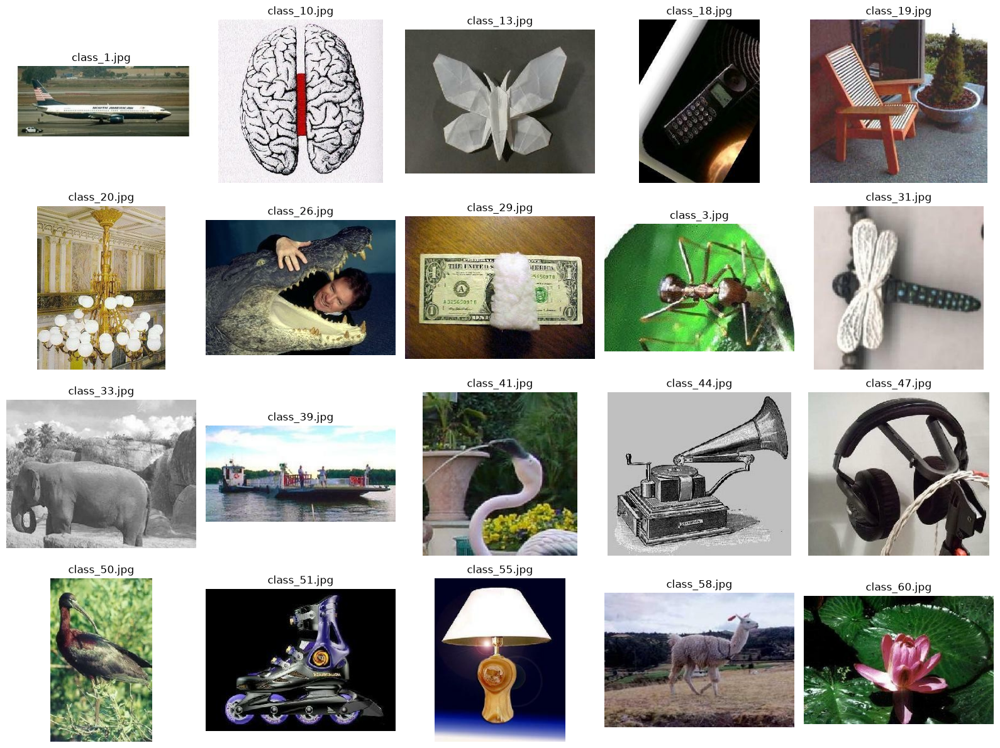

In [15]:
image_paths = sorted(Path("images").glob("*.jpg"))
fig, panels = plt.subplots(4, 5, figsize=(16, 12))
for panel, path in zip(panels.flat, image_paths):
    panel.imshow(Image.open(path))
    panel.set_title(path.name)
for panel in panels.flat:
    panel.axis("off")
plt.tight_layout()
plt.show()


In [16]:
import torch.nn.functional as F
image_paths = sorted(Path("images").glob("*.jpg"))
assert len(image_paths) > 0, "The image collection is empty."
image_embeddings = []
model.eval()
for filename in image_paths:
    with Image.open(filename) as raw_image:
        picture = raw_image.convert("RGB")
    prepared = processor(images=picture, return_tensors="pt")
    prepared = {k: v.to(device) for k,v in prepared.items()}
    with torch.no_grad():
        features = model.get_image_features(**prepared)
    if not isinstance(features, torch.Tensor):
        features = getattr(features, "pooler_output", None) if hasattr(features,"pooler_output") else features.image_embeds
    image_embeddings.append(F.normalize(features, p=2, dim=-1).cpu().flatten())
image_embeddings = torch.stack(image_embeddings)
torch.save(dict(paths=[str(p) for p in image_paths], embeddings=image_embeddings),
           "clip_image_database.pt")
print("Indexed:", len(image_paths), "embedding size:", image_embeddings.size(1))


Indexed: 38 embedding size: 512


In [17]:
norms = torch.linalg.vector_norm(image_embeddings, ord=2, dim=1)
print("Norms of initial vectors:", norms[:5])
print("All approximately one:", torch.allclose(norms, torch.ones_like(norms), atol=1e-4))


Norms of initial vectors: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
All approximately one: True


Search request: a person playing football
1 images/class_85.jpg cosine=0.2725
2 images/class_84.jpg cosine=0.2243
3 images/class_97.jpg cosine=0.2186
4 images/class_10.jpg cosine=0.2179
5 images/class_7.jpg cosine=0.2123


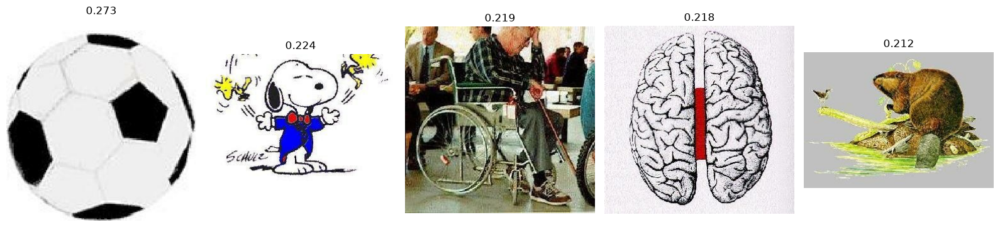

In [18]:
def search_images(query, top_k=5):
    encoded = processor(text=[query], padding=True, return_tensors="pt")
    encoded = {key: value.to(device) for key, value in encoded.items()}
    with torch.no_grad():
        text_embedding = model.get_text_features(**encoded)
    if not isinstance(text_embedding, torch.Tensor):
        text_embedding = text_embedding.pooler_output if hasattr(text_embedding, "pooler_output") else text_embedding.text_embeds
    text_embedding = F.normalize(text_embedding, p=2, dim=1).cpu().flatten()
    similarities = torch.mv(image_embeddings, text_embedding)
    best_indices = torch.argsort(similarities, descending=True)[:min(top_k,len(image_paths))]
    return [(str(image_paths[idx]), similarities[idx].item()) for idx in best_indices.tolist()]

query = "a person playing football"
top_results = search_images(query, top_k=5)
print(f"Search request: {query}")
for position, (filename, value) in enumerate(top_results, 1):
    print(position, filename, f"cosine={value:.4f}")
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for panel, match in zip(axes, top_results):
    filename, value = match
    panel.imshow(Image.open(filename))
    panel.set_title(f"{value:.3f}")
    panel.axis("off")
for panel in axes[len(top_results):]:
    panel.axis("off")
plt.tight_layout()
plt.show()


### Exercise 8 — Answers

**Q20. What is the most similar image?**

CLIP returned **images/class_85.jpg** at the top of the retrieved list (similarity **0.2725**).

**Q21. Is it semantically relevant?**

**PARTIALLY**. There is a ball.

**Q22. Why does this method not require image labels?**

No labels are needed at search time because the text query and stored images are compared through learned vector similarities instead of matching categorical tags.

**Q23. Give one real-world application of semantic image retrieval.**

A media production team could locate archived pictures using phrases such as "a crowded street at sunset" without manually annotating every photograph.


# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
Projection Layer
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

### Exercise 9 — Answers

**Q24. What is the role of the vision encoder?**

It identifies and encodes visual patterns in an input image as feature representations.

**Q25. Why is a projection layer required?**

The projection module connects the visual encoder to the language model by mapping image features into the model's expected embedding format.

**Q26. What is the role of the language model?**

It conditions its next-word generation on the question and visual features, creating the final description or answer.


## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [19]:
from huggingface_hub import hf_hub_download
from pathlib import Path

Path("models").mkdir(exist_ok=True)
MODEL_REPO = "mys/ggml_llava-v1.5-7b"
model_path = hf_hub_download(
    repo_id=MODEL_REPO, filename="ggml-model-q4_k.gguf", local_dir="models"
)
old_projector = hf_hub_download(
    repo_id=MODEL_REPO, filename="mmproj-model-f16.gguf", local_dir="models"
)
print("GGUF model path:", model_path)
print("Original projector path:", old_projector)


GGUF model path: /root/research/clip-llava-lab/CM/models/ggml-model-q4_k.gguf
Original projector path: /root/research/clip-llava-lab/CM/models/mmproj-model-f16.gguf


In [20]:
from gguf import GGUFReader

new_mmproj = hf_hub_download(
    repo_id="second-state/Llava-v1.5-7B-GGUF",
    filename="llava-v1.5-7b-mmproj-model-f16.gguf",
    local_dir="models",
)
reader = GGUFReader(new_mmproj)
print("Compatible projector:", new_mmproj)
print("Projector fields:", [k for k in reader.fields if "projector" in k.lower()])


Compatible projector: /root/research/clip-llava-lab/CM/models/llava-v1.5-7b-mmproj-model-f16.gguf
Projector fields: ['clip.has_llava_projector', 'clip.projector_type']


In [21]:
from llama_cpp import Llama
from llama_cpp.llama_chat_format import Llava15ChatHandler

chat_handler = Llava15ChatHandler(clip_model_path=str(new_mmproj), verbose=False)
llava = Llama(
    model_path=str(model_path), chat_handler=chat_handler,
    n_ctx=4096, n_threads=16, n_batch=512,
    n_gpu_layers=0, verbose=False
)
print("LLaVA model available")


LLaVA model available


In [22]:
import base64
import mimetypes
from pathlib import Path

def ask_llava(image_path, question, max_tokens=150):
    picture = Path(image_path)
    mime = mimetypes.guess_type(picture.name)[0] or "image/jpeg"
    encoded = base64.b64encode(picture.read_bytes()).decode("ascii")
    payload = f"data:{mime};base64,{encoded}"
    content = [
        {"type": "image_url", "image_url": {"url": payload}},
        {"type": "text", "text": question},
    ]
    response = llava.create_chat_completion(
        messages=[{"role": "user", "content": content}],
        max_tokens=max_tokens, temperature=0.1,
    )
    return response["choices"][0]["message"]["content"]


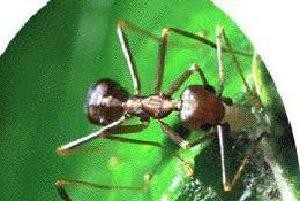

In [23]:
from IPython.display import display

image_path = "images/class_3.jpg"
with Image.open(image_path) as preview:
    display(preview.copy())


In [24]:
questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

llava_answers = []

for i, question in enumerate(questions, start=1):
    print(f"\nQuestion {i}: {question}")

    answer = ask_llava(image_path, question, max_tokens=180)

    llava_answers.append({
        "Question": question,
        "LLaVA Answer": answer
    })

    print(f"Answer: {answer}")
    print("-" * 60)


Question 1: What is happening in this image?


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What is happening in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 742 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 2426 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 886 ms


Answer:  The image features a close-up of a leaf with a spider and an ant on it. The spider is positioned on the left side of the leaf, while the ant is on the right side. The ant appears to be climbing up the leaf, while the spider is sitting on the leaf. The scene captures the interaction between these two different species in their natural environment.
------------------------------------------------------------

Question 2: How many people are visible?


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: How many people are visible?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 727 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3114 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 619 ms
mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: 

Answer: 0
------------------------------------------------------------

Question 3: What objects can you identify?


encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 725 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 20418 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 48704 ms


Answer: 1. A leaf
2. A spider
3. A leaf
4. A leaf
5. A leaf
6. A leaf
7. A leaf
8. A leaf
9. A leaf
10. A leaf
11. A leaf
12. A leaf
13. A leaf
14. A leaf
15. A leaf
16. A leaf
17. A leaf
18. A leaf
19. A leaf
20. A leaf
21. A leaf
22. A leaf
23. A leaf
24. A leaf
25. A leaf
26. A leaf
27. A leaf
28. A leaf
29. A leaf
30. A leaf
31. A leaf
32
------------------------------------------------------------

Question 4: Describe the image in detail.


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Describe the image in detail.ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 848 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 48201 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 48798 ms


Answer:  The image features a close-up of a spider and an ant on a leaf. The spider is positioned on the left side of the leaf, while the ant is on the right side. The spider appears to be looking at the ant, creating an interesting interaction between the two insects. The leaf provides a natural backdrop for this captivating scene.
------------------------------------------------------------


In [26]:
import pandas as pd

df_ex10 = pd.DataFrame(llava_answers)
display(df_ex10)

,Question,LLaVA Answer
0,What is happening in this image?,The image features a close-up of a leaf with ...
1,How many people are visible?,0
2,What objects can you identify?,1. A leaf\n2. A spider\n3. A leaf\n4. A leaf\n...
3,Describe the image in detail.,The image features a close-up of a spider and...


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

class_1.jpg


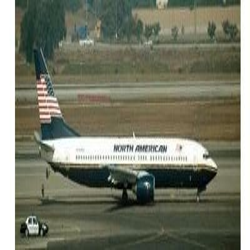

class_10.jpg


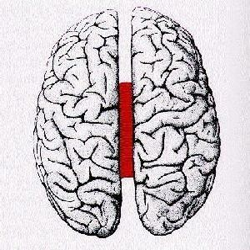

class_13.jpg


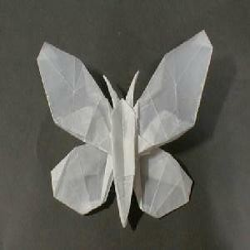

class_18.jpg


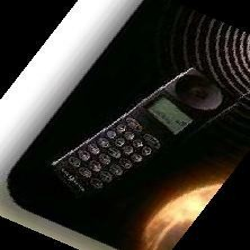

class_19.jpg


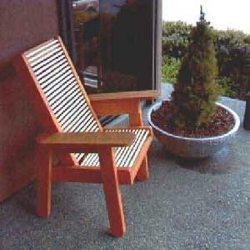

In [27]:
from pathlib import Path
from IPython.display import display

image_paths = sorted(Path("images").glob("class_*.jpg"))[:5]
assert len(image_paths) == 5, "Five class images are required for VQA."
questions = [
    "What is the main subject of this image?",
    "How many people are visible in this image?",
    "What objects can you identify?",
    "What is happening in this image?",
    "Describe the image in one sentence.",
]
for path in image_paths:
    print(path.name)
    with Image.open(path) as picture:
        display(picture.copy().resize((250, 250)))


In [28]:
vqa_results = []
for path in image_paths:
    for question in questions:
        reply = ask_llava(path, question, max_tokens=120)
        vqa_results.append({
            "Image": path.name, "Question": question,
            "LLaVA Answer": reply, "Human Evaluation": None,
        })
        print(path.name, "|", question, "|", reply)

df_vqa = pd.DataFrame(vqa_results)
display(df_vqa)


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What is the main subject of this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 724 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 5341 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 738 ms


class_1.jpg | What is the main subject of this image? |  The main subject of this image is a large passenger jet, specifically a North American airliner, sitting on the runway.


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: How many people are visible in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 729 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 4883 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 1502 ms


class_1.jpg | How many people are visible in this image? | 1 person is visible in the image.


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What objects can you identify?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 723 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 6203 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 4896 ms


...

mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What is happening in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 731 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3750 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 1777 ms


class_19.jpg | What is happening in this image? |  The image features an outdoor setting with a red and white striped wooden chair placed on a concrete floor. The chair is positioned near a window, and there is a potted plant nearby. The scene is captured in two different angles, one showing the chair from the front and the other from the side. The combination of the chair, potted plant, and window creates a cozy and inviting atmosphere.


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Describe the image in one sentence.ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 735 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 9361 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 757 ms


class_19.jpg | Describe the image in one sentence. | 2 pictures of a red and white striped chair in front of a window.


,Image,Question,LLaVA Answer,Human Evaluation
0,class_1.jpg,What is the main subject of this image?,The main subject of this image is a large pas...,None
1,class_1.jpg,How many people are visible in this image?,1 person is visible in the image.,None
2,class_1.jpg,What objects can you identify?,"1. A large passenger jet airplane, possibly a ...",None
3,class_1.jpg,What is happening in this image?,The image features a large North American air...,None
4,class_1.jpg,Describe the image in one sentence.,A North American airplane is on the runway.,None
5,class_10.jpg,What is the main subject of this image?,The main subject of this image is a close-up ...,None
6,class_10.jpg,How many people are visible in this image?,0,None
7,class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white backgrou...,None
8,class_10.jpg,What is happening in this image?,The image features a close-up of a human brai...,None
9,class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through it.,None


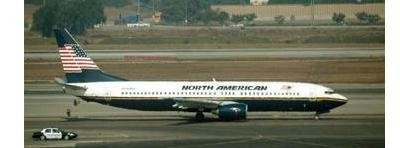

Image,Question,LLaVA Answer,Human Evaluation
class_1.jpg,What is the main subject of this image?,"The main subject of this image is a large passenger jet, specifically a North American airliner, sitting on the runway.",None
class_1.jpg,How many people are visible in this image?,1 person is visible in the image.,None
class_1.jpg,What objects can you identify?,"1. A large passenger jet airplane, possibly a North American airliner, sitting on the runway.\n2. A car, possibly a police car, parked near the airplane.\n3. A person standing near the airplane.\n4. A truck parked near the airplane.\n5. A few trees in the background.",None
class_1.jpg,What is happening in this image?,"The image features a large North American airplane parked on the runway at an airport. The airplane is positioned on the tarmac, and there are several people around it, likely attending to various tasks or preparing for the flight. In addition to the airplane, there are a few cars and a truck visible in the scene, possibly providing support services or transportation for the passengers and crew.",None
class_1.jpg,Describe the image in one sentence.,A North American airplane is on the runway.,None


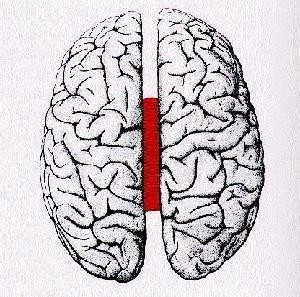

Image,Question,LLaVA Answer,Human Evaluation
class_10.jpg,What is the main subject of this image?,"The main subject of this image is a close-up of a human brain, with a red line drawn through it.",None
class_10.jpg,How many people are visible in this image?,0,None
class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white background\n4. A red line on the brain\n5. A white background with a red line on the brain\n6. A white background with a red line on the brain\n7. A white background with a red line on the brain\n8. A white background with a red line on the brain\n9. A white background with a red line on the brain\n10. A white background with a red line on the brain,None
class_10.jpg,What is happening in this image?,"The image features a close-up of a human brain, with a red line drawn through the center of it. The brain is shown in a black and white image, which highlights the contrast between the red line and the surrounding brain tissue. The red line divides the brain into two equal halves, creating a visually striking and memorable representation of the human brain.",None
class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through it.,None


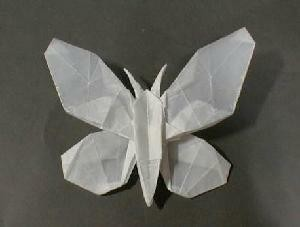

Image,Question,LLaVA Answer,Human Evaluation
class_13.jpg,What is the main subject of this image?,1. A butterfly made out of paper.,None
class_13.jpg,How many people are visible in this image?,0,None
class_13.jpg,What objects can you identify?,1. Butterfly\n2. Paper\n3. Black background,None
class_13.jpg,What is happening in this image?,"In the image, there is a close-up of a paper butterfly, which is a creative and intricate paper craft. The butterfly is made from folded paper and is placed on a black background. The paper butterfly is positioned in the center of the image, capturing the viewer's attention. The paper craft is a unique and artistic representation of a butterfly, showcasing the skill and creativity involved in its creation.",None
class_13.jpg,Describe the image in one sentence.,3D paper butterfly on a black background.,None


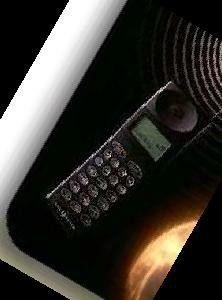

Image,Question,LLaVA Answer,Human Evaluation
class_18.jpg,What is the main subject of this image?,The main subject of this image is a cell phone.,None
class_18.jpg,How many people are visible in this image?,0,None
class_18.jpg,What objects can you identify?,1. A cell phone\n2. A keypad\n3. A screen\n4. A speaker\n5. A camera\n6. A microphone\n7. A phone number\n8. A battery\n9. A display\n10. A dial pad\n11. A phone\n12. A view of the back of a cell phone\n13. A view of the back of a cell phone with a camera\n14. A view of the back of a cell phone with a camera and a microphone\n15. A view of the back,None
class_18.jpg,What is happening in this image?,"The image features a close-up of a cell phone, with its screen displaying a number pad. The phone is placed on a surface, possibly a table or a desk. The focus of the image is on the cell phone, highlighting its screen and the number pad.",None
class_18.jpg,Describe the image in one sentence.,2000's era cell phone with a screen and buttons.,None


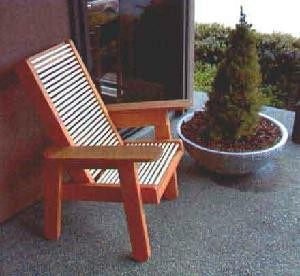

Image,Question,LLaVA Answer,Human Evaluation
class_19.jpg,What is the main subject of this image?,"The main subject of this image is a wooden chair, which is placed on a sidewalk or patio.",None
class_19.jpg,How many people are visible in this image?,0,None
class_19.jpg,What objects can you identify?,1. A red and white striped chair.\n2. A large pot or planter.\n3. A small tree or bush.\n4. A window.\n5. A door.\n6. A bench.\n7. A potted plant.\n8. A window sill.\n9. A door sill.,None
class_19.jpg,What is happening in this image?,"The image features an outdoor setting with a red and white striped wooden chair placed on a concrete floor. The chair is positioned near a window, and there is a potted plant nearby. The scene is captured in two different angles, one showing the chair from the front and the other from the side. The combination of the chair, potted plant, and window creates a cozy and inviting atmosphere.",None
class_19.jpg,Describe the image in one sentence.,2 pictures of a red and white striped chair in front of a window.,None


In [29]:
from IPython.display import HTML
pd.set_option("display.max_colwidth", None)
for path in image_paths:
    display(Image.open(path).copy())
    subset = df_vqa.loc[df_vqa["Image"] == path.name]
    display(HTML(subset.to_html(index=False, escape=True)))


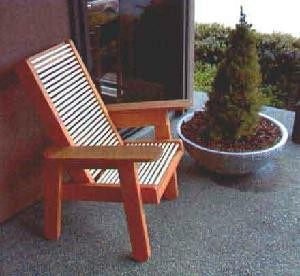

Question: What is the main subject of this image?
Response:  The main subject of this image is a wooden chair, which is placed on a sidewalk or patio.


Human score (0/1):  1


Question: How many people are visible in this image?
Response: 0


Human score (0/1):  1


Question: What objects can you identify?
Response: 1. A red and white striped chair.
2. A large pot or planter.
3. A small tree or bush.
4. A window.
5. A door.
6. A bench.
7. A potted plant.
8. A window sill.
9. A door sill.


...

Human score (0/1):  0


Question: Describe the image in one sentence.
Response: 2 pictures of a red and white striped chair in front of a window.


Human score (0/1):  0


Evaluation completed.


,Image,Question,LLaVA Answer,Human Evaluation
0,class_1.jpg,What is the main subject of this image?,"The main subject of this image is a large passenger jet, specifically a North American airliner, sitting on the runway.",1
1,class_1.jpg,How many people are visible in this image?,1 person is visible in the image.,0
2,class_1.jpg,What objects can you identify?,"1. A large passenger jet airplane, possibly a North American airliner, sitting on the runway.\n2. A car, possibly a police car, parked near the airplane.\n3. A person standing near the airplane.\n4. A truck parked near the airplane.\n5. A few trees in the background.",1
3,class_1.jpg,What is happening in this image?,"The image features a large North American airplane parked on the runway at an airport. The airplane is positioned on the tarmac, and there are several people around it, likely attending to various tasks or preparing for the flight. In addition to the airplane, there are a few cars and a truck visible in the scene, possibly providing support services or transportation for the passengers and crew.",0
4,class_1.jpg,Describe the image in one sentence.,A North American airplane is on the runway.,1
5,class_10.jpg,What is the main subject of this image?,"The main subject of this image is a close-up of a human brain, with a red line drawn through it.",1
6,class_10.jpg,How many people are visible in this image?,0,1
7,class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white background\n4. A red line on the brain\n5. A white background with a red line on the brain\n6. A white background with a red line on the brain\n7. A white background with a red line on the brain\n8. A white background with a red line on the brain\n9. A white background with a red line on the brain\n10. A white background with a red line on the brain,0
8,class_10.jpg,What is happening in this image?,"The image features a close-up of a human brain, with a red line drawn through the center of it. The brain is shown in a black and white image, which highlights the contrast between the red line and the surrounding brain tissue. The red line divides the brain into two equal halves, creating a visually striking and memorable representation of the human brain.",1
9,class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through it.,1


In [30]:
# Human assessment: inspect each answer and record 1 (correct) or 0 (incorrect).
# Enter scores in the same order as the displayed table for each image.
from IPython.display import clear_output

manual_scores = []
for path in image_paths:
    clear_output(wait=True)
    display(Image.open(path).copy())
    for _, record in df_vqa[df_vqa["Image"] == path.name].iterrows():
        print("Question:", record["Question"])
        print("Response:", record["LLaVA Answer"])
        score = input("Human score (0/1): ").strip()
        while score not in ("0", "1"):
            score = input("Enter only 0 or 1: ").strip()
        manual_scores.append(int(score))

df_vqa["Human Evaluation"] = manual_scores
print("Evaluation completed.")
display(df_vqa)


In [31]:
correct_answers = int(df_vqa["Human Evaluation"].sum())
total_questions = len(df_vqa)
vqa_accuracy = 100 * correct_answers / total_questions
print(f"Correct answers: {correct_answers}/{total_questions}")
print(f"VQA accuracy: {vqa_accuracy:.2f}%")


Correct answers: 17/25
VQA accuracy: 68.00%


In [32]:
df_vqa.to_csv("llava_vqa_evaluation.csv", index=False)
print("CSV evaluation exported.")
display(df_vqa)


CSV evaluation exported.


,Image,Question,LLaVA Answer,Human Evaluation
0,class_1.jpg,What is the main subject of this image?,"The main subject of this image is a large passenger jet, specifically a North American airliner, sitting on the runway.",1
1,class_1.jpg,How many people are visible in this image?,1 person is visible in the image.,0
2,class_1.jpg,What objects can you identify?,"1. A large passenger jet airplane, possibly a North American airliner, sitting on the runway.\n2. A car, possibly a police car, parked near the airplane.\n3. A person standing near the airplane.\n4. A truck parked near the airplane.\n5. A few trees in the background.",1
3,class_1.jpg,What is happening in this image?,"The image features a large North American airplane parked on the runway at an airport. The airplane is positioned on the tarmac, and there are several people around it, likely attending to various tasks or preparing for the flight. In addition to the airplane, there are a few cars and a truck visible in the scene, possibly providing support services or transportation for the passengers and crew.",0
4,class_1.jpg,Describe the image in one sentence.,A North American airplane is on the runway.,1
5,class_10.jpg,What is the main subject of this image?,"The main subject of this image is a close-up of a human brain, with a red line drawn through it.",1
6,class_10.jpg,How many people are visible in this image?,0,1
7,class_10.jpg,What objects can you identify?,1. A brain\n2. A red line\n3. A white background\n4. A red line on the brain\n5. A white background with a red line on the brain\n6. A white background with a red line on the brain\n7. A white background with a red line on the brain\n8. A white background with a red line on the brain\n9. A white background with a red line on the brain\n10. A white background with a red line on the brain,0
8,class_10.jpg,What is happening in this image?,"The image features a close-up of a human brain, with a red line drawn through the center of it. The brain is shown in a black and white image, which highlights the contrast between the red line and the surrounding brain tissue. The red line divides the brain into two equal halves, creating a visually striking and memorable representation of the human brain.",1
9,class_10.jpg,Describe the image in one sentence.,3D image of a brain with a red line through it.,1


## Exercise 11 — Answers

#### Q27 — What is VQA accuracy?

VQA accuracy reports how often a model's answers are judged correct on the selected visual questions:

For the five test images, the manual review marked **17 of 25** answers correct, i.e. **68%**.

#### Q28 — Which types of questions are difficult for LLaVA?

Based on the review, challenging questions shows that the system can produce confident statements that are not fully supported by the image.


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

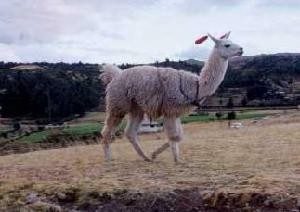

In [33]:
image_path_ex12 = "images/class_58.jpg"  # Visually verify: no bicycle.
display(Image.open(image_path_ex12).copy())


In [34]:
questions_ex12 = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?",
]
answers_ex12 = []
for idx, question in enumerate(questions_ex12, start=1):
    reply = ask_llava(image_path_ex12, question, max_tokens=120)
    answers_ex12.append({"Question": question, "LLaVA Answer": reply})
    print(f"{idx}. {question}\n   {reply}\n")


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: Is there a bicycle in this image?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 726 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 5159 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 2024 ms


1. Is there a bicycle in this image?
   0



mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What color is the bicycle?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 728 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 2758 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 609 ms
mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: pr

2. What color is the bicycle?
   0



encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 725 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 4318 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 1161 ms


3. Where is the bicycle located?
   1. The bicycle is located in a field.



In [35]:
df_ex12 = pd.DataFrame(answers_ex12)
pd.set_option("display.max_colwidth", None)
display(df_ex12)


,Question,LLaVA Answer
0,Is there a bicycle in this image?,0
1,What color is the bicycle?,0
2,Where is the bicycle located?,1. The bicycle is located in a field.


In [ ]:
df_ex12.to_csv("llava_hallucination_results.csv", index=False)
print("Hallucination observations saved.")


## Exercise 12 — Answers

#### Q29 — Does the bicycle actually exist?

**No.** The test image **images/class_58.jpg** should be visually confirmed to contain no bicycle before scoring the model.

#### Q30 — Did LLaVA invent information?

**Yes**. for last question, it gives: The bicycle is located in a field.

#### Q31 — What is a visual hallucination?

It is an image-related claim produced by a model even though the picture does not provide evidence for that claim.

#### Q32 — Why can a multimodal model hallucinate?

A generative model learns likely text continuations and may accept false assumptions in a question. Image ambiguity, imperfect coupling between modalities, and prior language patterns can further encourage unsupported details.


# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

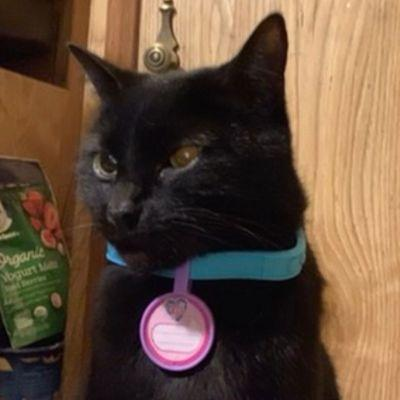

In [36]:
image_path_ex13 = "image.jpg"
assert Path(image_path_ex13).is_file(), f"Image missing: {image_path_ex13}"
image_ex13 = Image.open(image_path_ex13).convert("RGB")
display(image_ex13)


In [37]:
# Reuse the CLIP model loaded for the earlier exercises.
clip_model = model
clip_processor = processor
prompts = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
batch = clip_processor(text=prompts, images=image_ex13, padding=True, return_tensors="pt")
batch = {key: tensor.to(device) for key, tensor in batch.items()}
with torch.inference_mode():
    logits = clip_model(**batch).logits_per_image[0]
probabilities = logits.softmax(dim=-1).cpu()
df_clip_ex13 = pd.DataFrame({"Description": prompts, "Probability": probabilities.numpy()})
display(df_clip_ex13)
best_index = int(probabilities.argmax())
print("CLIP prediction:", prompts[best_index], f"({probabilities[best_index]:.2%})")


,Description,Probability
0,a photo of a cat,0.988897
1,a photo of a dog,0.007242
2,a photo of a horse,0.003861


CLIP prediction: a photo of a cat (98.89%)


In [38]:
question_ex13 = "What animal is present in the image? Describe its appearance."
llava_answer_ex13 = ask_llava(image_path_ex13, question_ex13, max_tokens=180)
print("Question:", question_ex13)
print("LLaVA:", llava_answer_ex13)


mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What animal is present in the image? Describe its appearance.ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 907 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 51115 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 46558 ms


Question: What animal is present in the image? Describe its appearance.
LLaVA: 1. A black cat is present in the image. It has a blue collar around its neck and is wearing a heart-shaped tag. The cat appears to be looking at the camera.

2. The black cat is wearing a blue collar and a heart-shaped tag. It is standing in front of a wooden wall, possibly in a kitchen setting. The cat seems to be looking at the camera.


In [39]:
comparison = pd.DataFrame([
    ["Input", "Image + candidate descriptions", "Image + a question"],
    ["Main output", "Similarity ranking", "Generated text"],
    ["Zero-shot classification", "Supported via prompts", "Possible via prompting"],
    ["Image retrieval", "Supported", "Not its principal feature"],
    ["Text generation", "No", "Yes"],
    ["VQA", "Not directly", "Yes"],
    ["Open-ended response", "No", "Yes"],
], columns=["Property", "CLIP", "LLaVA"])
display(comparison)


,Property,CLIP,LLaVA
0,Input,Image + candidate descriptions,Image + a question
1,Main output,Similarity ranking,Generated text
2,Zero-shot classification,Supported via prompts,Possible via prompting
3,Image retrieval,Supported,Not its principal feature
4,Text generation,No,Yes
5,VQA,Not directly,Yes
6,Open-ended response,No,Yes


## Exercise 13 — Answers

#### Q33 — Which model is better suited to image classification?

**CLIP** is designed to compare images against textual class candidates. In this run, its leading candidate was **a photo of a cat** with relative score **98.9%**.

#### Q34 — Which model is better for image description?

**LLaVA**, since it can produce complete natural-language descriptions; CLIP is mainly a comparison and retrieval model.

#### Q35 — Which model is better for visual question answering?

**LLaVA** is the suitable model for conversational VQA, because it can generate responses conditioned on both a picture and the supplied question.

#### Q36 — Explain the fundamental difference between CLIP and LLaVA.

CLIP performs **contrastive alignment** and assigns similarity scores to image–text combinations. LLaVA uses **vision features as inputs to a language generator**, so it can give longer, open-ended answers instead of only ranking candidate descriptions.


# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

# Final Mini-Project — Multimodal Image Assistant

## 1. Project Objective

This mini-project demonstrates a two-stage multimodal workflow while retaining a direct image-question mode. It brings together semantic search and free-form answer generation inside one notebook.

## 2. Architecture

- **Direct mode:** Selected Image → LLaVA + Question → Answer

## 3. Tools and Implementation

The application uses Python, A **GGUF LLaVA 1.5 7B** model processes the final image-question pair. The interface is implemented with callable notebook functions rather than a separate website.

## 4. Example Runs

**Direct Q&A:** Image **[IMAGE]**; question **[QUESTION]**; answer **[OBSERVED RESULT]**.


These examples should be replaced by observations from a fresh run.

## 5. Mini-Project Conclusion

The combined workflow offers a straightforward way to locate candidate pictures and then explore one of them conversationally. CLIP handles the matching stage, while LLaVA handles language generation. Results still depend on the available image gallery and the models' ability to avoid unsupported visual claims, with CPU execution adding response latency.


In [40]:
# This mini-project uses notebook functions; no interactive widget extension is needed.
from pathlib import Path
from IPython.display import display


In [41]:
# Reuse the already-loaded CLIP components instead of initializing them a second time.
clip_model = model
clip_processor = processor
clip_model.eval()
print("CLIP ready for the mini-project")


CLIP ready for the mini-project


In [42]:
# The compatible projector and LLaVA model were loaded in Exercise 10.
assert "llava" in globals(), "Run the Exercise 10 LLaVA initialization first."
print("LLaVA ready for the mini-project")


LLaVA ready for the mini-project


In [43]:
# Reuse the common ask_llava(image_path, question) helper from Exercise 10.
assert callable(ask_llava)
print("Image-question helper is available")


Image-question helper is available


In [44]:
for name in ("clip_model", "clip_processor", "llava", "ask_llava"):
    print(f"{name}: {'ready' if name in globals() else 'missing'}")


clip_model: ready
clip_processor: ready
llava: ready
ask_llava: ready


In [45]:
# Final mini-project prerequisites.
from pathlib import Path
from PIL import Image
from IPython.display import display

device = next(clip_model.parameters()).device
assert callable(ask_llava), "The LLaVA helper must be initialized."
print("CLIP device:", device)


CLIP device: cpu


In [46]:
def search_images(query, top_k=5):
    query_batch = clip_processor(text=[query], return_tensors="pt", padding=True, truncation=True).to(device)
    with torch.inference_mode():
        vector = clip_model.get_text_features(**query_batch)
        if not isinstance(vector, torch.Tensor):
            vector = vector.pooler_output
        vector = torch.nn.functional.normalize(vector, dim=-1)
    similarities = torch.mv(image_database_embeddings, vector.cpu().squeeze(0))
    best = torch.argsort(similarities, descending=True)[:min(top_k, len(image_database_paths))]
    return [{"path": image_database_paths[idx], "score": similarities[idx].item()}
            for idx in best.tolist()]


In [47]:
# Index all class images for CLIP text-to-image retrieval.
image_database_paths = sorted(Path("images").glob("class_*.jpg"))
assert len(image_database_paths) >= 5, "Need at least five images."

image_vectors = []
with torch.inference_mode():
    for path in image_database_paths:
        picture = Image.open(path).convert("RGB")
        batch = clip_processor(images=picture, return_tensors="pt").to(device)
        embedding = clip_model.get_image_features(**batch)
        if not isinstance(embedding, torch.Tensor):
            embedding = embedding.pooler_output
        embedding = embedding / embedding.norm(dim=-1, keepdim=True)
        image_vectors.append(embedding.cpu())
image_database_embeddings = torch.cat(image_vectors, dim=0)
print("Indexed:", len(image_database_paths), "images")
print("Embedding dimensions:", image_database_embeddings.shape)


Indexed: 38 images
Embedding dimensions: torch.Size([38, 512])


In [48]:
def multimodal_qa(image_path, question):
    selected = Path(image_path)
    print(f"Analyzing: {selected.name}")
    display(Image.open(selected).convert("RGB"))
    result = ask_llava(selected, question, max_tokens=180)
    print("Question:", question)
    print("Model response:", result)
    return result


In [49]:
def multimodal_search_and_qa(query, question, top_k=5, selected_rank=1):
    retrieved = search_images(query, top_k=top_k)
    if not 1 <= selected_rank <= len(retrieved):
        raise IndexError("Select a rank between 1 and the number of matches")
    print(f"Search: {query}")
    for rank, match in enumerate(retrieved, 1):
        print(f"Rank {rank}: {match['path'].name} (cosine: {match['score']:.3f})")
        display(Image.open(match["path"]).convert("RGB"))
    chosen = str(retrieved[selected_rank - 1]["path"])
    explanation = ask_llava(chosen, question, max_tokens=180)
    print(f"Chosen rank: {selected_rank}; question: {question}")
    print("LLaVA says:", explanation)
    return retrieved, chosen, explanation


Analyzing: image.jpg


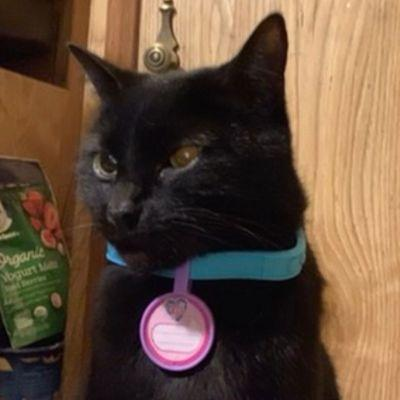

mtmd_group_mergeable_bitmaps: no merging for part index 1
add_text: A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.USER: 
add_media: preproc_out has 1 entries, grid_x = 0, grid_y = 0, has_overview = 0
image_tokens->nx = 576
image_tokens->ny = 1
batch_f32 size = 1
add_text: What animal is visible in this image and how would you describe it?ASSISTANT: 
encoding image slice...
clip_encode: copying image 1/1 to input buffer (nx=336, ny=336)
clip_encode: output embedding shape [4096, 576, 1]
image slice encoded in 728 ms
decoding image batch 1/2, n_tokens_batch = 512
image decoded (batch 1/2) in 3502 ms
decoding image batch 2/2, n_tokens_batch = 64
image decoded (batch 2/2) in 669 ms


Question: What animal is visible in this image and how would you describe it?
Model response: 1. A black cat is visible in the image.
2. The cat is wearing a blue collar with a heart-shaped charm.
3. The cat is standing in front of a wooden cabinet.
4. The cat appears to be looking at the camera.
5. The image is a split photo, showing the cat from two different angles.


In [50]:
# Mode A demonstration
answer_mode_a = multimodal_qa(
    "image.jpg", "What animal is visible in this image and how would you describe it?"
)


# Final Laboratory Conclusion

This series of exercises examined two approaches to multimodal learning: **contrastive image–text matching** with CLIP and **image-conditioned text generation** with LLaVA.

### CLIP evaluation

The classification experiment achieved **10/10 = 100%** on the selected examples, and the first image returned for the football text search was **images/class_85.jpg** with score **0.2725**.

### LLaVA evaluation

Across five images and 25 questions, manual assessment found **17** correct answers, corresponding to **68%**. In the absent-bicycle experiment.

### Comparison of approaches

CLIP's shared embedding space is useful when the output must be a **ranking or similarity estimate**. LLaVA's vision-to-language pipeline supports **open-ended responses** and user questions. The two systems should be regarded as complementary building blocks.

### Limitations and next steps

The experiments involve a modest set of test pictures, results may vary with chosen queries, and running multimodal inference without a GPU is relatively slow. Future work could use a broader evaluation set, accelerate model execution and incorporate answer-grounding checks.

**Conclusion:** The practical work connects representation learning to generation and shows how both can support an image assistant, provided that retrieval results and generated descriptions are evaluated critically.
